# Matplotlib exercises (with Git)

List 1: ex 1-6 - from https://www.w3resource.com/graphics/matplotlib/basic/index.php (15 ex)

List 2: ex 7-10 - from https://www.w3resource.com/graphics/matplotlib/scatter/index.php (6 ex)

List 3: ex 11 - from https://www.w3resource.com/graphics/matplotlib/piechart/index.php (4 ex)

List 4: ex 12-14 - from https://www.w3resource.com/graphics/matplotlib/barchart/index.php (17 ex)

##### Graphs to-do list:

Stem plot

Fill the area between two lines (that mouth from ICF)

Stackplot/steam graphs

Polar axis scatter plot

Black body radiaton graph for some real stars

Mars' and Mercury's retrograde movement animation

Event plot?


#### Other must-see big areas:

Subplots (https://realpython.com/python-matplotlib-guide/#understanding-pltsubplots-notation)

Colors (Berkeley!!)

Axesgrid?

Animation?

#### Maybe:

3d visualization of a Gaussian distribution

3d bar charts

Timeline with data, labels, etc

In [1]:
# importing every library we'll use
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### 1. Multicolored line with markevery and ticked patheffect

1.1) y = x

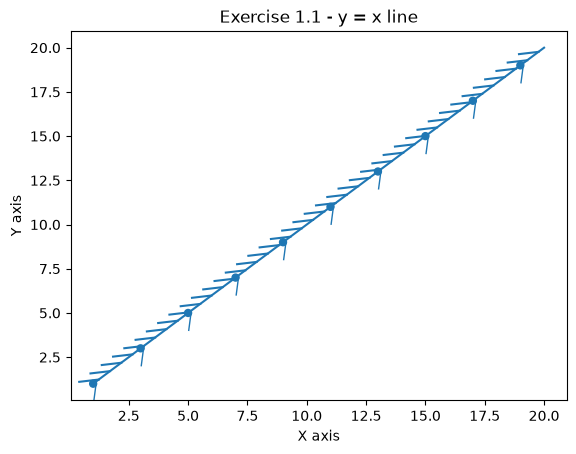

In [38]:
from matplotlib import patheffects as pth


plt.title('Exercise 1.1 - y = x line')
plt.xlabel('X axis')
plt.ylabel('Y axis') 
x = [i for i in range(1,21)]
y = x
plt.plot(x,y, markevery=2, marker='o', markersize=5, path_effects=[pth.withTickedStroke(spacing=10, angle=150)])
plt.show()

1.2) y = 5x, adjusting the axes to preserve the slope

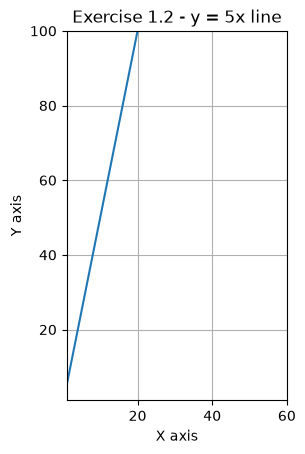

In [2]:
plt.title('Exercise 1.2 - y = 5x line')
plt.xlabel('X axis')
plt.ylabel('Y axis') 
x = [i for i in range(1,21)]
y = [5*i for i in range(1,21)]
plt.gca().set_aspect('equal') # saving the aspect ratio of the graph
plt.xlim(1,60) # extending x axis for better visualization keeping the domain restriction
plt.ylim(1,100)
plt.grid(True)
plt.plot(x,y)
plt.show()

### 2. Line with a turning point and gradient background

Gradient background code taken from https://matplotlib.org/stable/gallery/lines_bars_and_markers/gradient_bar.html

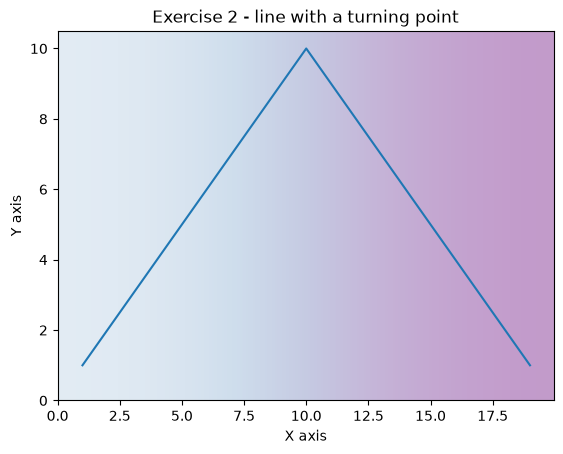

In [43]:
def gradient_image(ax, direction=0.3, cmap_range=(0, 1), **kwargs):
    """
    Draw a gradient image based on a colormap.

    Parameters
    ----------
    ax : Axes
        The Axes to draw on.
    direction : float
        The direction of the gradient. This is a number in
        range 0 (=vertical) to 1 (=horizontal).
    cmap_range : float, float
        The fraction (cmin, cmax) of the colormap that should be
        used for the gradient, where the complete colormap is (0, 1).
    **kwargs
        Other parameters are passed on to `.Axes.imshow()`.
        In particular, *cmap*, *extent*, and *transform* may be useful.
    """
    phi = direction * np.pi / 2
    v = np.array([np.cos(phi), np.sin(phi)])
    X = np.array([[v @ [1, 0], v @ [1, 1]],
                  [v @ [0, 0], v @ [0, 1]]])
    a, b = cmap_range
    X = a + (b - a) / X.max() * X
    im = ax.imshow(X, interpolation='bicubic', clim=(0, 1),
                   aspect='auto', **kwargs)
    return im


# Generating the graph

fig, ax = plt.subplots()
# background image
gradient_image(ax, direction=1, extent=(0, 1, 0, 1), transform=ax.transAxes,
               cmap="BuPu", cmap_range=(0.2, 0.8), alpha=0.5)
ax.set_title('Exercise 2 - line with a turning point')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')

x = [i for i in range(1,20)]
y = [i for i in range(1,11)] + [i for i in range(9,0,-1)]
plt.plot(x,y)

### Exercise 3 - multiple line charts with varied linestyles

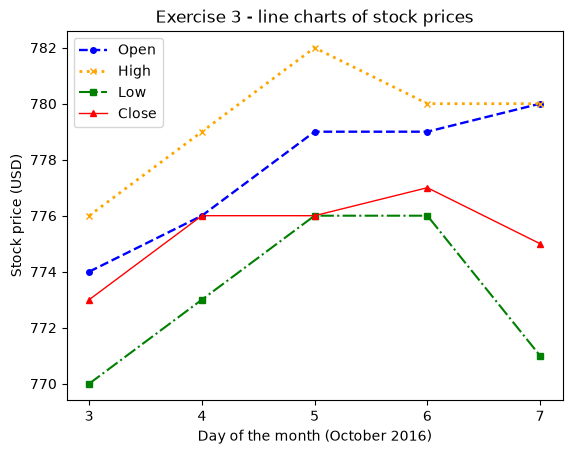

In [4]:
data = """10-03-16,774.25,776.065002,769.5,772.559998
10-04-16,776.030029,778.710022,772.890015,776.429993
10-05-16,779.309998,782.070007,775.650024,776.469971
10-06-16,779,780.47998,775.539978,776.859985
10-07-16,779.659973,779.659973,770.75,775.080017"""
data = data.splitlines()
plt.title('Exercise 3 - line charts of stock prices')
plt.xlabel('Day of the month (October 2016)')
plt.ylabel('Stock price (USD)')
x = [i for i in range(3,8)]
y_open = [round(float(line.split(',')[1]), 0) for line in data]
y_high = [round(float(line.split(',')[2]), 0) for line in data]
y_low = [round(float(line.split(',')[3]), 0) for line in data]
y_close = [round(float(line.split(',')[4]), 0) for line in data]
plt.plot(x, y_open, label = "Open", linestyle='dashed', color='blue', linewidth=1.7, marker = 'o', markersize = 4)
plt.plot(x, y_high, label = "High", linestyle='dotted', color='orange', linewidth=2, marker='x', markersize = 4) 
plt.plot(x, y_low, label = "Low", linestyle='dashdot', color='green', linewidth=1.5, marker='s', markersize = 4) 
plt.plot(x, y_close, label = "Close", linestyle='solid', color='red', linewidth=1, marker='^', markersize = 4) 
plt.legend(loc='upper left') # changing the legend position
plt.xticks([i for i in range(3,8)])
plt.show()

### Exercise 4 - random positions of two particles

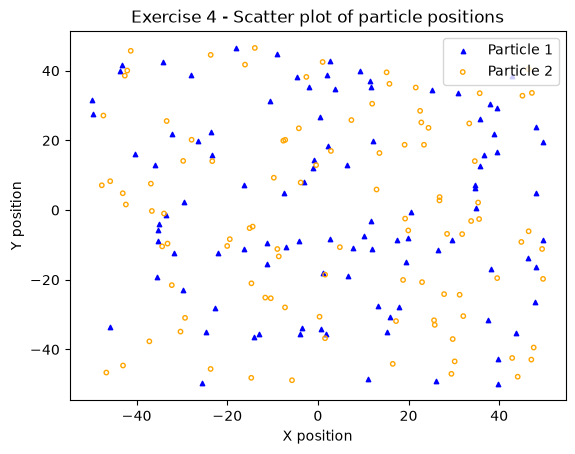

In [5]:
x1 = np.random.uniform(-50.0,50.0,size=100)
y1 = np.random.uniform(-50.0,50.0,size=100)
plt.scatter(x1,y1, label='Particle 1', color='blue', marker='^', s=10)
x2 = np.random.uniform(-50.0,50.0,size=100)
y2 = np.random.uniform(-50.0,50.0,size=100)
plt.scatter(x2,y2, label='Particle 2', color='orange', marker='o', facecolors='none', s=10)
plt.xlabel('X position')
plt.ylabel('Y position')
plt.title('Exercise 4 - Scatter plot of particle positions')
plt.legend()
plt.show()

### Exercise 5 - scatter function values

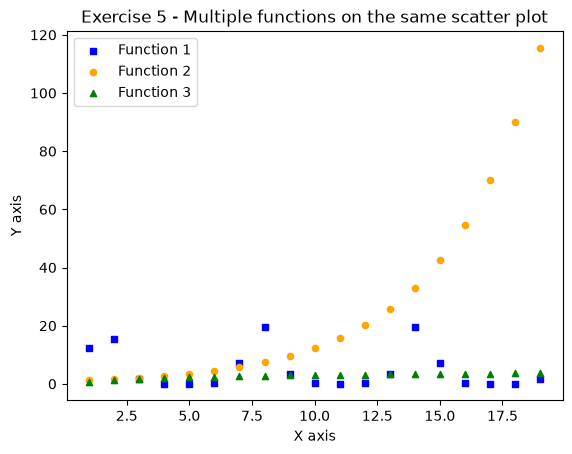

In [6]:
x = [i for i in range(1,20)]
y1 = [(np.exp(3*np.sin(i))) for i in x]
plt.scatter(x, y1, label='Function 1', color='blue', marker='s', s=20)
y2 = [np.exp(i/4) for i in x]
plt.scatter(x, y2, label='Function 2', color='orange', marker='o', s=20)
y3 = [np.log(2*i) for i in x]
plt.scatter(x, y3, label='Function 3', color='green', marker='^', s=20)
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.title('Exercise 5 - Multiple functions on the same scatter plot')
plt.legend()
plt.show()


### Exercise 6 - customizing grid lines

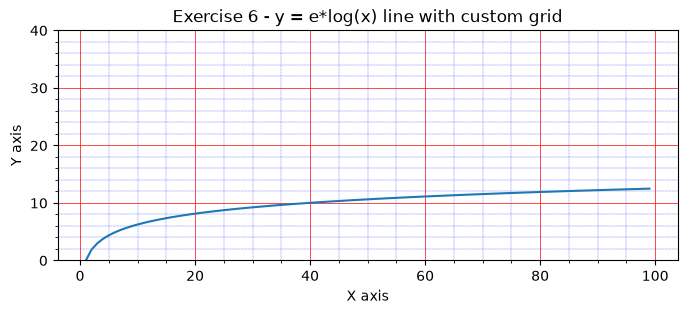

In [7]:
x = [i for i in range(1,100)]
y = [np.e*np.log(i) for i in x]
plt.figure(figsize=(8,4))
plt.title('Exercise 6 - y = e*log(x) line with custom grid')
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.minorticks_on()
plt.gca().set_aspect('equal')
plt.grid(which='major', color='red', linestyle='-', linewidth=0.5)
plt.grid(which='minor', color='blue', linestyle='--', linewidth=0.2)
plt.plot(x, y)
plt.yticks([i for i in range(0,41,10)])
plt.ylim(0,40)
plt.show()

### Exercise 7 - dynamic-changing markers

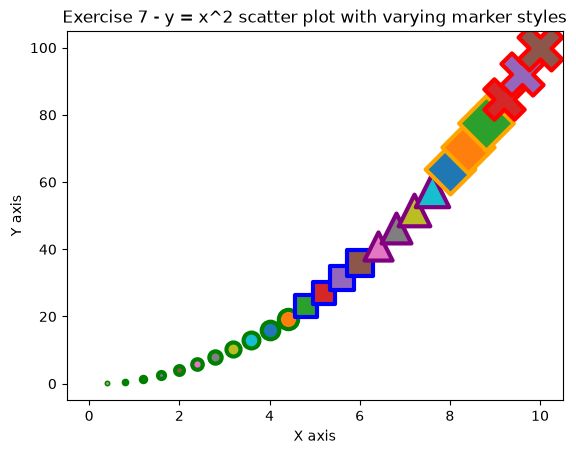

In [8]:
# generating data
x = np.linspace(0, 10, 26)
y = x**2
# defining the functions
def circle_color(a):
    if a < 20:
        color = 'green'
    elif a < 40:
        color = 'blue'
    elif a<60:
        color = 'purple'
    elif a<80:
        color = 'orange'
    else:
        color = 'red'
    return color
def marker(a):
    if a < 20:
        marker = 'o'
    elif a < 40:
        marker = 's'
    elif a<60:
        marker = '^'
    elif a<80:
        marker = 'D'
    else:
        marker = 'X'
    return marker
# customizing styles
sizes = [10*y for y in y]
colors = [circle_color(a) for a in y]
markers = [marker(a) for a in y]
# now plotting
plt.title('Exercise 7 - y = x^2 scatter plot with varying marker styles')
plt.xlabel('X axis')
plt.ylabel('Y axis')
for xi,yi,si,ci,mi in zip(x,y,sizes,colors,markers):
    plt.scatter(xi, yi, s=si, edgecolors=ci, marker=mi, linewidth=3)
plt.plot()
plt.show()

### Exercise 8 - math vs science grades

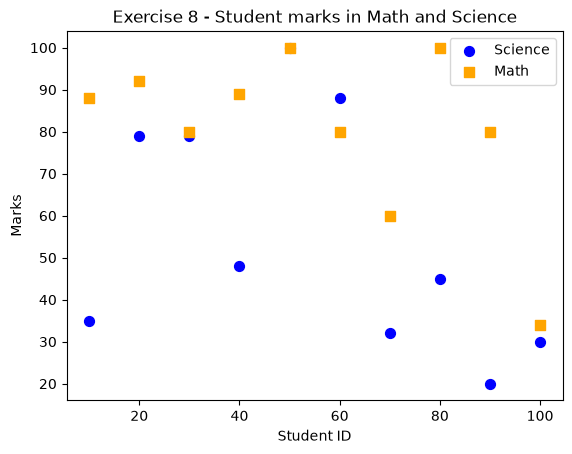

In [9]:
# defining the data
x = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
y = x
math_marks = [88, 92, 80, 89, 100, 80, 60, 100, 80, 34]
science_marks = [35, 79, 79, 48, 100, 88, 32, 45, 20, 30]
# creating the graph
plt.xlabel('Student ID')
plt.ylabel('Marks')
plt.title('Exercise 8 - Student marks in Math and Science')
for xi, scmi, mmi in zip(x, science_marks, math_marks):
    plt.scatter(xi, scmi, color='blue', marker='o', s=50, label='Science' if xi==10 else "")
    plt.scatter(xi, mmi, color='orange', marker='s', s=50, label='Math' if xi==10 else "")
plt.legend()
plt.show()

### Exercise 9 - three different groups comparing height and weight

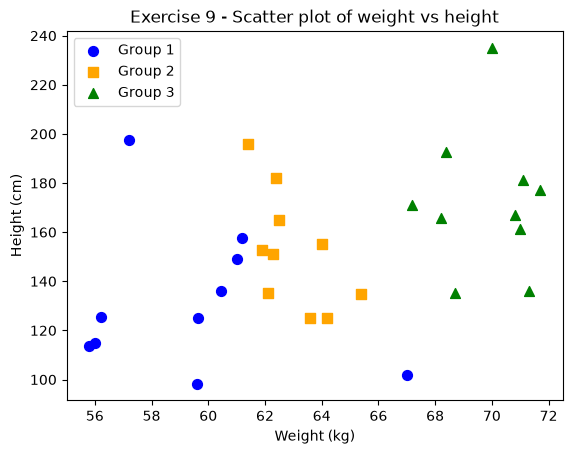

In [10]:
# defining the data
weight1=[67,57.2,59.6,59.64,55.8,61.2,60.45,61,56.23,56]
height1=[101.7,197.6,98.3,125.1,113.7,157.7,136,148.9,125.3,114.9]
weight2=[61.9,64,62.1,64.2,62.3,65.4,62.4,61.4,62.5,63.6]
height2=[152.8,155.3,135.1,125.2,151.3,135,182.2,195.9,165.1,125.1]
weight3=[68.2,67.2,68.4,68.7,71,71.3,70.8,70,71.1,71.7]
height3=[165.8,170.9,192.8,135.4,161.4,136.1,167.1,235.1,181.1,177.3]
weight = weight1 + weight2 + weight3
height = height1 + height2 + height3

# creating the graph
plt.title('Exercise 9 - Scatter plot of weight vs height')
plt.xlabel('Weight (kg)')
plt.ylabel('Height (cm)')
plt.scatter(weight1, height1, color='blue', marker='o', s=50, label='Group 1')
plt.scatter(weight2, height2, color='orange', marker='s', s=50, label='Group 2')
plt.scatter(weight3, height3, color='green', marker='^', s=50, label='Group 3')
plt.legend()
plt.show()

### Exercise 10 - reading data from a .csv file and plotting

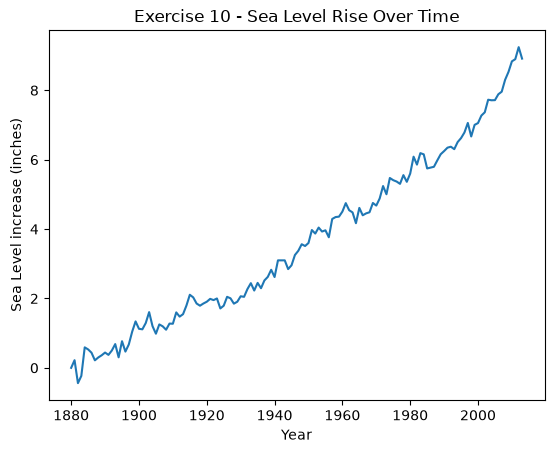

In [11]:
dataframe = pd.read_csv('C:\\Users\\danye\\Downloads/epa-sea-level.csv')
years = dataframe['Year']
sea_levels = dataframe['CSIRO Adjusted Sea Level']

plt.xlabel('Year')
plt.ylabel('Sea Level increase (inches)')
plt.title('Exercise 10 - Sea Level Rise Over Time')
plt.plot(years, sea_levels)
plt.show()

Making $y = e^{3sin(x)}$ graph for fun

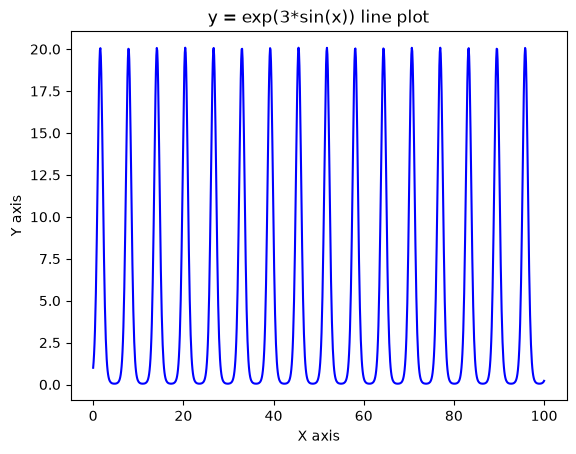

In [12]:
x = np.linspace(0, 100, 1000)
y1 = [(np.exp(3*np.sin(i))) for i in x]
plt.plot(x, y1, color='blue')
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.title('y = exp(3*sin(x)) line plot')
plt.show()

### Exercise 11 - complete pie chart of programming languages popularity

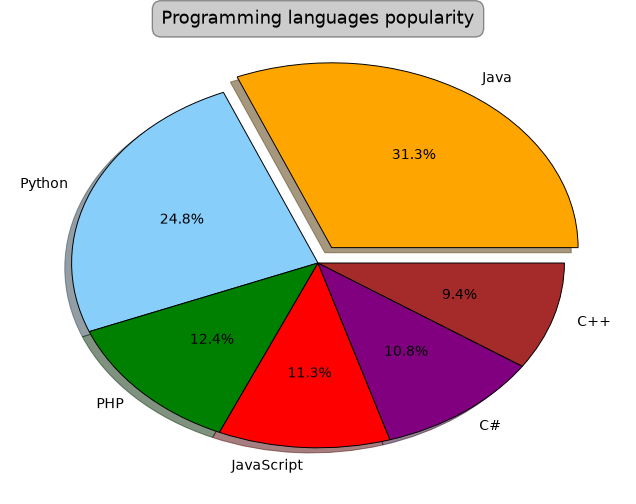

In [13]:
# generating data
langs = ['Java', 'Python', 'PHP', 'JavaScript', 'C#', 'C++']
popularity = [22.2, 17.6, 8.8, 8, 7.7, 6.7]

# defining parameters
explodes = [0.1,0,0,0,0,0]
customcolors = ['orange', 'lightskyblue', 'green', 'red', 'purple', 'brown']

# creating the bar chart
fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(
        popularity,
        labels=langs,
        explode = explodes,
        autopct='%1.1f%%',
        colors=customcolors,
        shadow = True,
        wedgeprops={'edgecolor': 'black', 'linewidth': 0.7}
        )
ax.set_aspect(0.75) # along with the figsize, this flattens the graph, making it to seem tilted
plt.title(
    'Programming languages popularity',
    fontsize = 13,
    bbox =dict(
        facecolor='gray',
        alpha=0.4,
        edgecolor = 'black',
        boxstyle='round,pad=0.5'))
plt.show()

### Exercise 12 - Vertical same-colored bars  with double grid, numbers, labels, customized border

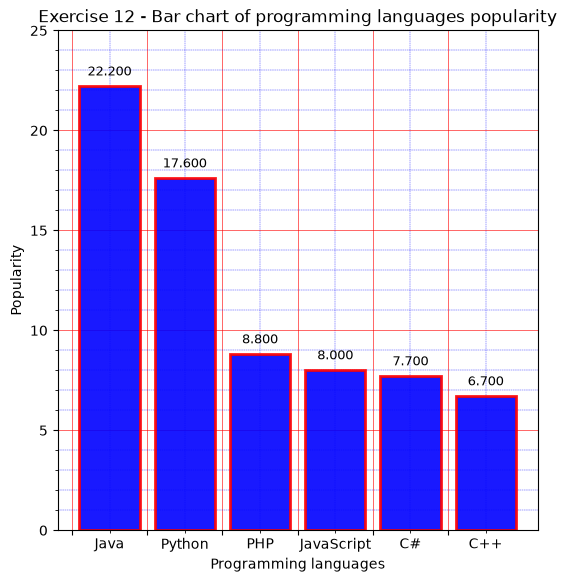

In [14]:
# Defining data and parameters
langs = ['Java', 'Python', 'PHP', 'JavaScript', 'C#', 'C++']
langpos = np.arange(len(langs))
popularity = [22.2, 17.6, 8.8, 8, 7.7, 6.7]
bar_labels = [f'{p}%' for p in popularity] 

# Creating the figure and axes

fig, ax = plt.subplots(figsize=(6,8.33))
ax.set_xlabel('Programming languages')
ax.set_ylabel('Popularity')
ax.set_title('Exercise 12 - Bar chart of programming languages popularity')
ax.bar(langpos, popularity, label=bar_labels, color='blue', alpha = 0.9,edgecolor='red', linewidth=2)

# Customizing the grid

ax.set_axisbelow(True)
ax.minorticks_on()
ax.set_xticks(langpos-0.5) # MAJOR tick sitting on the gutters between the bars
ax.set_xticks(langpos, minor=True)
ax.set_xticklabels(langs, minor=True) # Correcting the labels position to the center of each bar
ax.set_xticklabels([], minor=False) # REMOVING the labels of the MAJOR ticks
ax.set_yticks(np.arange(0, 30, 5))
ax.grid(which='major', color='red', linestyle='-', linewidth=0.6, alpha=0.7)
ax.grid(which='minor', color='blue', linestyle='--', linewidth=0.3, alpha=0.9)

# Adding the labels on top of each bar

for x, y in zip(langpos, popularity):
    ax.text(
        x,                      # Positioning the text
        y + 0.4,                
        f"{y:.3f}",             # Formatted string with 3 decimals
        ha='center',            # Horizontal alignment (centered on bar)
        va='bottom',            # Vertical alignment
        fontsize=9
    )
# Finishing
ax.set_position([0.07, 0.3, 0.8, 0.6]) # in a normalized (0 to 1) scale: 0.07 left, 0.3 bottom, 0.8 width, 0.6 height
plt.show()

### Exercise 13 - horizontal multicolored dislocated multi-width bar plot

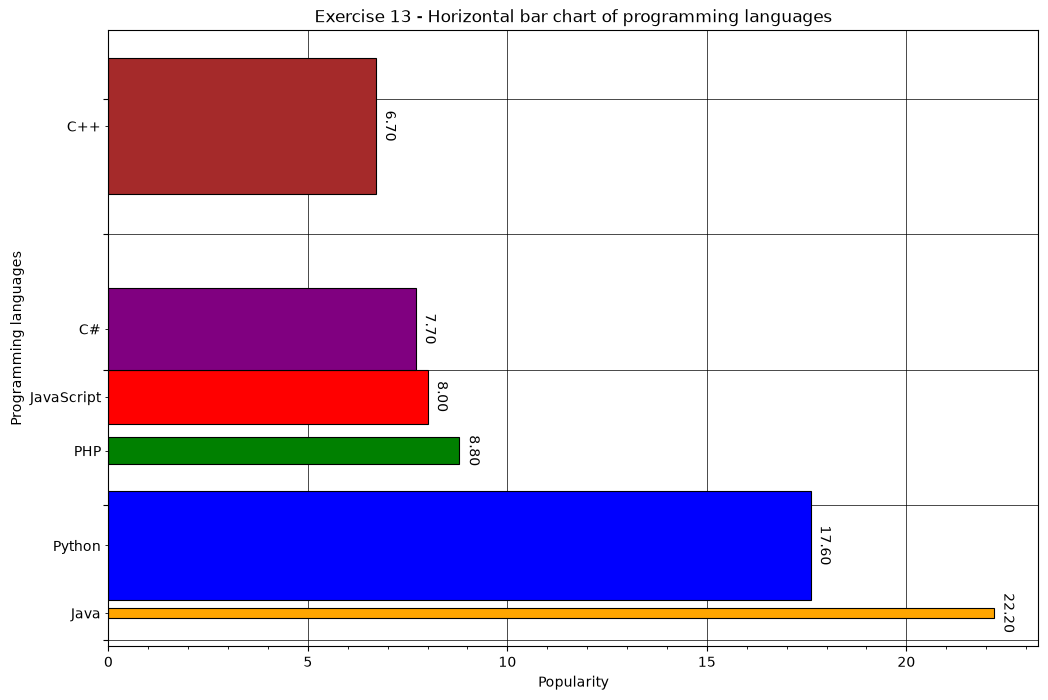

In [15]:
# Defining data and parameters
langs = ['Java', 'Python', 'PHP', 'JavaScript', 'C#', 'C++']
popularity = [22.2, 17.6, 8.8, 8, 7.7, 6.7]
langpos = np.array([1,3.5,7,9,11.5,19])
langwid = np.array([0.4, 4, 1, 2, 3, 5])
colors = ['orange', 'blue', 'green', 'red', 'purple', 'brown']
bar_labels = [f'{p}%' for p in popularity] 

# Generating the bar chart
fig, ax = plt.subplots(figsize=(12,8))
ax.set_ylabel('Programming languages')
ax.set_xlabel('Popularity')
ax.set_title('Exercise 13 - Horizontal bar chart of programming languages')
bars = ax.barh(langpos, popularity, height=langwid, color=colors, edgecolor='black', linewidth = 0.8) # creating an object to simplify the labeling of the bars
ax.bar_label(bars, fmt='%.2f', padding=5,rotation=270) 

# Correcting the y axis labels and enabling grid
ax.minorticks_on()
ax.set_yticks(langpos,minor='True')
ax.set_yticklabels(langs, minor='True') # placing the labels on their respective position
ax.set_yticklabels([], minor=False) # REMOVING the labels of the MAJOR ticks
ax.set_axisbelow(True)
ax.grid(which='major',color='black', linewidth=0.5)

# Finishing
plt.show()

### Exercise 14 - double bars plot

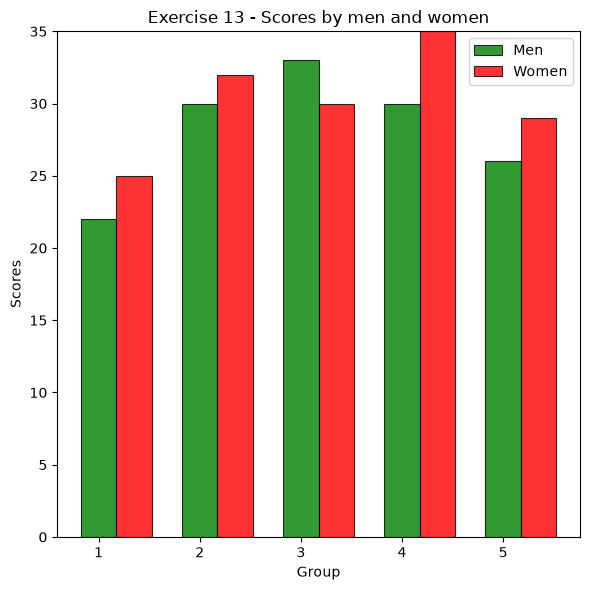

In [16]:
# Defining data and parameters

men = (22, 30, 33, 30, 26)
women = (25, 32, 30, 35, 29)
x = np.arange(1,6)
bar_width = 0.35

# Generating the plot
fig, ax = plt.subplots(figsize=(6,6))
ax.set_xlabel('Group')
ax.set_ylabel('Scores')
ax.set_title('Exercise 13 - Scores by men and women')
ax.bar(x, men, bar_width, color='g', label='Men', alpha=0.8, edgecolor='black',linewidth='0.8')
ax.bar(x + bar_width, women, bar_width, color='r', alpha=0.8, label = 'Women', edgecolor='black',linewidth='0.8') # slightly dislocating the women's bars so the both bars are shown

# Improving visualization and showing
ax.set_ylim(0,35)
plt.legend()
plt.tight_layout()
plt.show()

### Exercise 15 - inset plot zooming in the root of a function

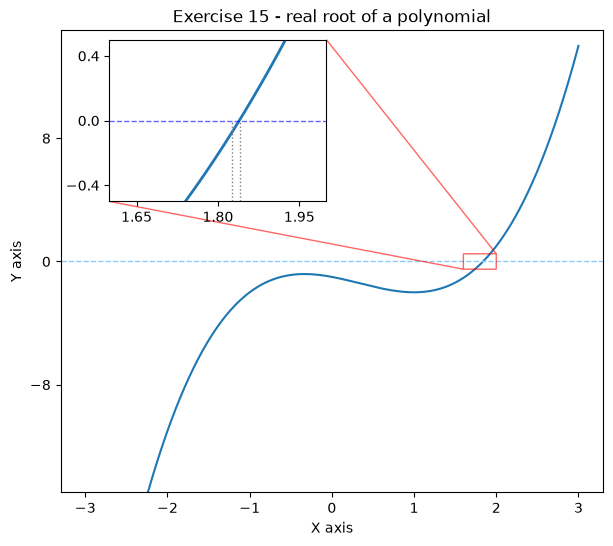

In [ ]:
# Generating the data
x = np.linspace(-3,3,1000)
y = [(a**3 - a**2 - a - 1) for a in x]

# Generating the main graph
fig,ax = plt.subplots(figsize=(7,6))
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_ylim(-15,15)

ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
ax.set_title('Exercise 15 - real root of a polynomial')
ax.plot(x, y)
ax.axhline(0, color='lightskyblue',ls='--', lw=1,)


# Generating the inset
axins = ax.inset_axes([0.09, 0.63, 0.4, 0.35])
axins.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
axins.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
axins.plot(x,y, lw=2)
axins.set_xlim(1.6,2)
axins.set_ylim(-0.5,0.5)
axins.axhline(color='blue', ls='--', lw=1, alpha=0.6)
axins.axvline(x=1.825, ymax = 0.5, color='grey', ls=':',lw=1)
axins.axvline(x=1.84, ymax = 0.5, color='grey', ls=':',lw=1)
ax.indicate_inset_zoom(axins, edgecolor="r", alpha=0.6) # indicating the zoom target

plt.show()

### Exercise 16 - surface, wireframe, contour and filled contour plots of the function $f(x) = sin(x)^{2} (3y-3)^{2}$

# AJOFYH48O2UWT VO43T 4PUT UHUIT GU4I2HT 34OY43



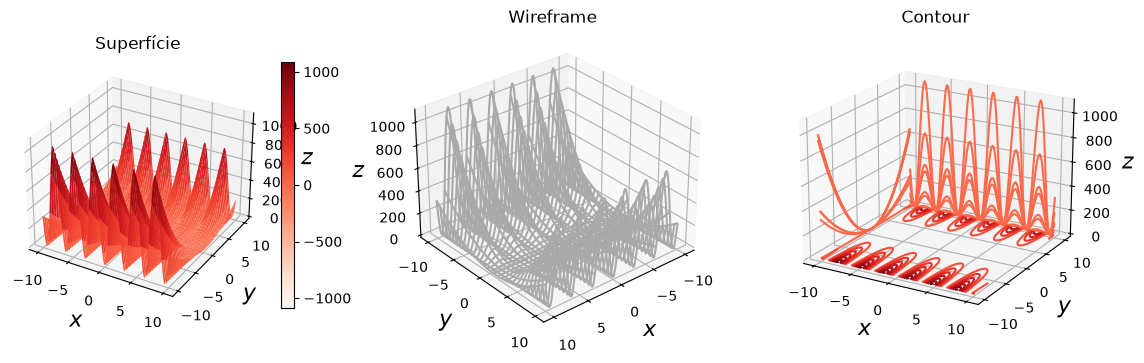

In [26]:
# CORRIGIR AS LEGENDAS AAAAAAA

# Gernerating the data
x = y = np.linspace(-10,10,150)
X, Y = np.meshgrid(x, y)
Z = (np.sin(X)**2)*((3*Y - 3)**2)


# Creating the graphs (colocar a colorbar e as legendas direito)
def title_labels(ax, title):
    ax.set_title(title)
    ax.set_xlabel("$x$", fontsize=16)
    ax.set_ylabel("$y$", fontsize=16)
    ax.set_zlabel("$z$", fontsize=16) 

fig,axes = plt.subplots(1,3, figsize=(14,4), subplot_kw={'projection': '3d'})
norm = mpl.colors.Normalize(-abs(Z).max(), abs(Z).max())

# First graph - surface

p = axes[0].plot_surface(X, Y, Z, antialiased=True, norm=norm, cmap=mpl.cm.Reds)
cb = fig.colorbar(p, ax=axes[0], shrink=0.8, )
title_labels(axes[0],'Superfície')

# Second graph - wireframe 

q = axes[1].plot_wireframe(X, Y, Z, rstride=5, cstride=5, antialiased=True, color="darkgrey")
axes[1].view_init(elev=30, azim=50)
title_labels(axes[1], "Wireframe")

# Third graph - contour plot

axes[2].contour(X, Y, Z, zdir='y', offset=10, norm=norm, cmap=mpl.cm.Reds)
axes[2].contour(X, Y, Z, zdir='x', offset=-10, norm=norm, cmap=mpl.cm.Reds)
axes[2].contour(X, Y, Z, zdir='z', offset=0, norm=norm, cmap=mpl.cm.Reds)
axes[2].view_init(elev=20, azim=-60)
title_labels(axes[2], "Contour")

plt.show()

### Exercise 17 - surface plot with contour projections


# AJOFYH48O2UWT VO43T 4PUT UHUIT GU4I2HT 34OY43

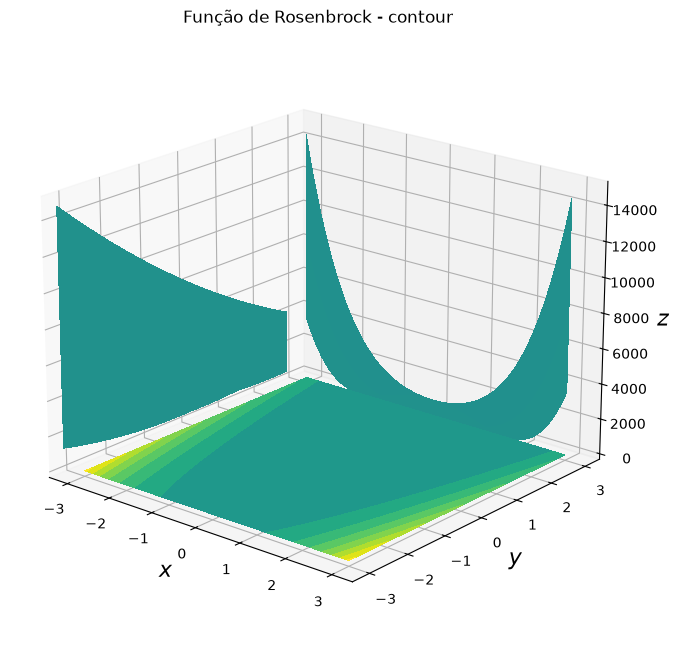

In [29]:
from mpl_toolkits.mplot3d import axes3d

# Gerando os dados
x = y = np.linspace(-3,3,100)
X,Y = np.meshgrid(x,y)
Z = 100 * (Y - X**2)**2 + (1 - X)**2

# Gerando o gráfico

fig,ax = plt.subplots(figsize=(8,8), subplot_kw={'projection': '3d'})
norm = mpl.colors.Normalize(-abs(Z).max(), abs(Z).max())

ax.set_title('Função de Rosenbrock - contour')
ax.set_xlabel("$x$", fontsize=16)
ax.set_ylabel("$y$", fontsize=16)
ax.set_zlabel("$z$", fontsize=16) 

ax.contourf(X, Y, Z, zdir='x', offset=-3.5, norm=norm, cmap=mpl.cm.viridis)
ax.contourf(X, Y, Z, zdir='y', offset=3, norm=norm, cmap=mpl.cm.viridis)
ax.contourf(X, Y, Z, zdir='z', offset=0, norm=norm, cmap=mpl.cm.viridis)
ax.view_init(elev=20, azim=-50)

plt.show()

### Exercise 18 - Stem plot of $f(x) = e^{sin(x)}$

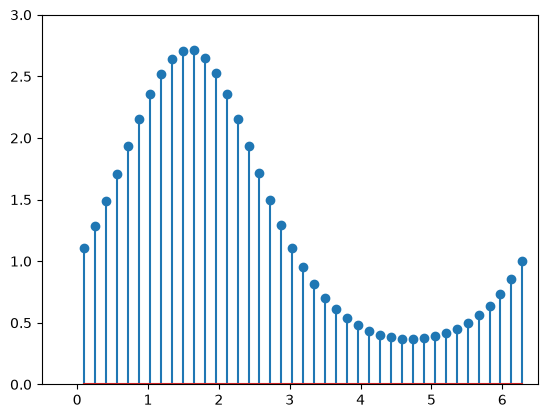

In [5]:
x = np.linspace(0.1, 2 * np.pi, 41)
y = np.exp(np.sin(x))

plt.stem(x, y)
plt.xlim(-0.5,6.5)
plt.ylim(0,3)
plt.show()